In [31]:
import pandas as pd
import os
parent_dir = '/work/magroup/skrieger/Syndri/data/xenium_noise_experiment/metrics_eval_layers_pooled_cosmx_X/'
metric_dirs = os.listdir(parent_dir)
tcell_files = sorted([os.path.join(parent_dir,x,'tcell_contamination_metrics_layers_pooled.csv') for x in metric_dirs if os.path.exists(os.path.join(parent_dir,x,'tcell_contamination_metrics_layers_pooled.csv'))])
tcell_df = pd.concat([pd.read_csv(f) for f in tcell_files]).reset_index(drop=True)
# sep_df = pd.read_csv('/work/magroup/skrieger/Syndri/data/xenium_noise_experiment/metrics_eval_layers_pooled/B10_B10/cell_type_separation_metrics_worstadj.csv')
# sep_df['tissue'].iloc[0]
tcell_df['dropout']= tcell_df['tissue'].apply(lambda x: x.split('_')[-1])

tcell_df['input_layer'].unique()

array(['X'], dtype=object)

In [32]:
tcell_df

,sample,target_cell_type_i,contaminating_cell_type_j,n_target_cells_total,n_proximal_to_j,n_distal_to_j,n_fit_cells,top_n,marker_overlap_n,marker_overlap_frac,...,group_achieved_removed_fractions,error,input_layer,evaluation_method,probability_layer,counts_layer,sample_replicate,dropout_label,dropout_fraction,dropout
0,st,neutrophil,tumor,16699.0,7062.0,9637.0,16699.0,20.0,5.0,0.25,...,NaN,NaN,X,baseline,NaN,X,Lung12,0pct,0.0,1pct
1,st,neutrophil,macrophage,16699.0,1452.0,15247.0,16699.0,20.0,9.0,0.45,...,NaN,NaN,X,baseline,NaN,X,Lung12,0pct,0.0,1pct
2,st,neutrophil,epithelial,16699.0,1434.0,15265.0,16699.0,20.0,4.0,0.20,...,NaN,NaN,X,baseline,NaN,X,Lung12,0pct,0.0,1pct
3,st,neutrophil,endothelial,16699.0,2839.0,13860.0,16699.0,20.0,9.0,0.45,...,NaN,NaN,X,baseline,NaN,X,Lung12,0pct,0.0,1pct
4,st,neutrophil,fibroblast,16699.0,7543.0,9156.0,16699.0,20.0,9.0,0.45,...,NaN,NaN,X,baseline,NaN,X,Lung12,0pct,0.0,1pct
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11064,st,monocyte,tumor,296.0,135.0,161.0,296.0,20.0,1.0,0.05,...,NaN,NaN,X,split,NaN,split_purified_counts_X,Lung6,0pct,0.0,1pct
11065,st,monocyte,fibroblast,296.0,69.0,227.0,296.0,20.0,0.0,0.00,...,NaN,NaN,X,split,NaN,split_purified_counts_X,Lung6,0pct,0.0,1pct
11066,st,monocyte,endothelial,296.0,73.0,223.0,296.0,20.0,3.0,0.15,...,NaN,NaN,X,split,NaN,split_purified_counts_X,Lung6,0pct,0.0,1pct
11067,st,monocyte,DC,296.0,53.0,243.0,296.0,20.0,6.0,0.30,...,NaN,NaN,X,split,NaN,split_purified_counts_X,Lung6,0pct,0.0,1pct


Text(0.5, 0.98, 'Strength of T-Cell Contamination vs Transcript dropout')

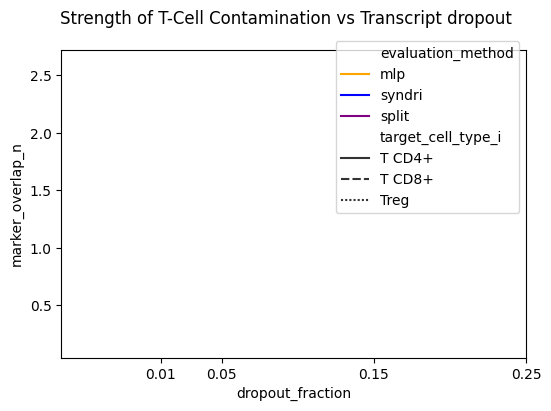

In [33]:
import seaborn as sns
import matplotlib.pyplot as plt
mal_df = tcell_df[(tcell_df['target_cell_type_i'].str.contains('T')) & 
                  (tcell_df['contaminating_cell_type_j'].str.contains('tumor'))&
                  # (tcell_df['dropout_fractiojn'])
                  (~tcell_df['target_removed_fraction'].isin([0.01,
                                                              0.02,
                                                              0.05,
                                                              0.1,
                                                            #   0.2,
                                                              ]))].reset_index(drop=True)
                  # (tcell_df['sample_replicate'].str.contains('_B1_'))].reset_index(drop=True)

fig,ax= plt.subplots(figsize=(6,4))
custom_colors = {
    'syndri': 'blue',  # Hex code
    'mlp': 'orange',     # Named color
    'split': 'purple'    # Shorthand notation
}
sns.lineplot(data=mal_df,x='dropout_fraction',y='marker_overlap_n',hue='evaluation_method',style='target_cell_type_i',ax=ax,errorbar=None,palette=custom_colors,hue_order=['mlp','syndri','split'])
ax.legend(bbox_to_anchor=(1,1.05))
ax.set_xticks([0.01,0.05,0.15,0.25])
fig.suptitle('Strength of T-Cell Contamination vs Transcript dropout')

In [4]:
mal_df.columns

Index(['sample', 'target_cell_type_i', 'contaminating_cell_type_j',
       'n_target_cells_total', 'n_proximal_to_j', 'n_distal_to_j',
       'n_fit_cells', 'top_n', 'marker_overlap_n', 'marker_overlap_frac',
       'overlap_genes', 'top_coef_genes', 'contaminating_type_markers',
       'zscore_mode', 'condition', 'tissue', 'source_file',
       'target_removed_fraction', 'admix_prob_threshold',
       'achieved_removed_fraction', 'cleaning_mode', 'probability_transform',
       'probability_removal_scale', 'cell_type_specific_removal',
       'group_admix_prob_thresholds', 'group_probability_removal_scales',
       'group_achieved_removed_fractions', 'error', 'input_layer',
       'evaluation_method', 'probability_layer', 'counts_layer',
       'sample_replicate', 'dropout_label', 'dropout_fraction', 'dropout'],
      dtype='object')

In [34]:
import ast
import itertools
from collections import Counter

import pandas as pd

filtered_df = mal_df.loc[
    mal_df["dropout_fraction"].eq(0.00)
].copy()

records = []

for method, method_df in filtered_df.groupby("evaluation_method"):
    for cell_type, ct_df in method_df.groupby("target_cell_type_i"):

        gene_lists = (
            ct_df["overlap_genes"]
            .dropna()
            .map(
                lambda x: ast.literal_eval(x)
                if isinstance(x, str)
                else x
            )
        )

        gene_counts = Counter(
            itertools.chain.from_iterable(gene_lists)
        )

        records.extend(
            {
                "evaluation_method": method,
                "cell_type": cell_type,
                "gene": gene,
                "count": count,
            }
            for gene, count in gene_counts.items()
        )

marker_counts = pd.DataFrame.from_records(
    records,
    columns=[
        "evaluation_method",
        "cell_type",
        "gene",
        "count",
    ],
)

marker_counts = marker_counts.sort_values(
    ["evaluation_method", "cell_type", "count"],
    ascending=[True, True, False],
).reset_index(drop=True)

In [ ]:
import anndata as ad
st_data = ad.read_h5ad('/work/magroup/skrieger/Syndri/data/xenium_noise_experiment/cosmx_nsclc_Lung9-Rep1_adata_annotated_dropout_1pct.h5ad')


In [ ]:

# ensembl_map=dict(zip(st_data.var.index,st_data.var['feature_name']))

Index(['ENSG00000181409', 'ENSG00000097007', 'ENSG00000143322',
       'ENSG00000159640', 'ENSG00000130234', 'ENSG00000213088',
       'ENSG00000144476', 'ENSG00000129048', 'ENSG00000107796',
       'ENSG00000163017',
       ...
       'ENSG00000111186', 'ENSG00000154764', 'ENSG00000188064',
       'ENSG00000143816', 'ENSG00000100219', 'ENSG00000143184',
       'ENSG00000143185', 'ENSG00000060138', 'ENSG00000176105',
       'ENSG00000128016'],
      dtype='object', name='index', length=958)

In [35]:
marker_counts['gene_name']=marker_counts['gene']#.map(ensembl_map)

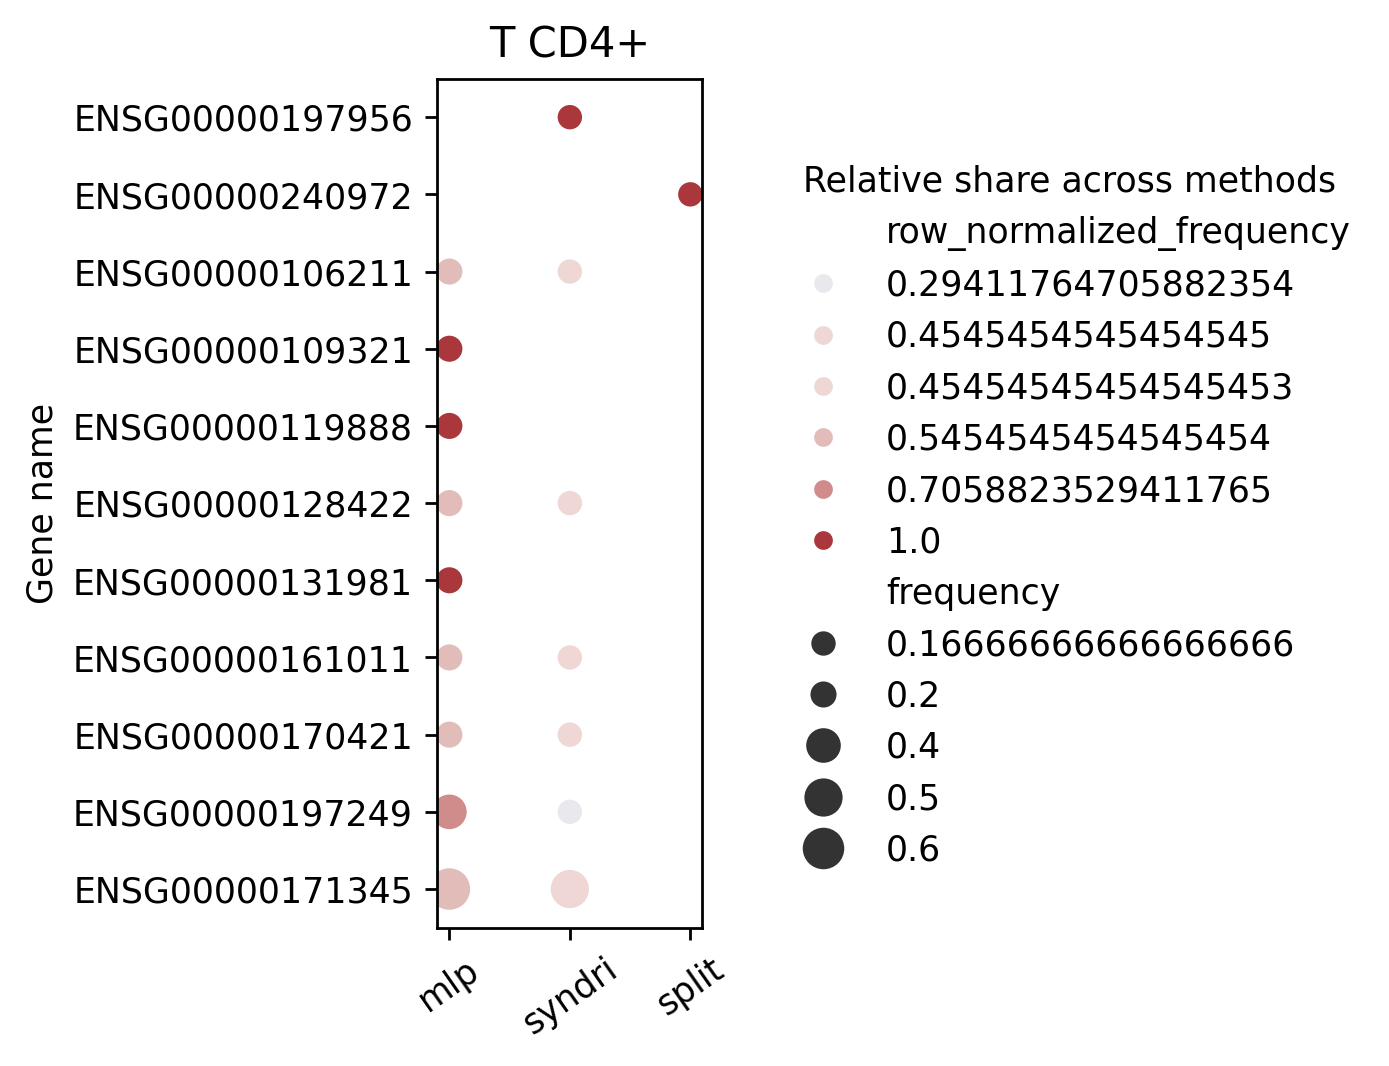

In [36]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
mal_df['evaluation_method']=pd.Categorical(mal_df['evaluation_method'],categories=['mlp','syndri','split'],ordered=True)
# Same subset used to construct marker_counts
filtered_df = mal_df.loc[
    mal_df["dropout_fraction"].eq(0.0)
].copy()

# Number of evaluations contributing to each method–cell-type group
evaluation_totals = (
    filtered_df
    .groupby(
        ["evaluation_method", "target_cell_type_i"],
        observed=True,
    )
    .size()
    .rename("n_evaluations")
    .reset_index()
    .rename(columns={"target_cell_type_i": "cell_type"})
)

# Convert counts into detection frequencies
plot_df = marker_counts.merge(
    evaluation_totals,
    on=["evaluation_method", "cell_type"],
    how="left",
)

plot_df["frequency"] = (
    plot_df["count"] / plot_df["n_evaluations"]
)

# Keep only the most informative genes within each cell type
n_genes = 20

gene_scores = (
    plot_df
    .groupby(
        ["cell_type", "gene_name"],
        observed=True,
    )["frequency"]
    .max()
    .reset_index()
)

top_genes = (
    gene_scores
    .sort_values(
        ["cell_type", "frequency"],
        ascending=[True, False],
    )
    .groupby("cell_type", observed=True)
    .head(n_genes)[["cell_type", "gene_name"]]
)

plot_df = plot_df.merge(
    top_genes,
    on=["cell_type", "gene_name"],
    how="inner",
)
method_order = ["mlp", "syndri", "split"]

plot_df["evaluation_method"] = pd.Categorical(
    plot_df["evaluation_method"],
    categories=method_order,
    ordered=True,
)

method_labels = {
    "mlp": "MLP",
    "syndri": "Syndri",
    "split": "SPLIT",
}

plot_df["method_label"] = (
    plot_df["evaluation_method"]
    .astype(str)
    .map(method_labels)
)

method_label_order = ["MLP", "Syndri", "SPLIT"]

plot_df = plot_df.sort_values("evaluation_method")
plot_df["row_normalized_frequency"] = (
    plot_df["frequency"]
    / plot_df.groupby(
        ["cell_type", "gene_name"],
        observed=True,
    )["frequency"].transform("sum")
)
n_genes_per_method = 8

top_by_method = (
    plot_df
    .sort_values(
        [
            "cell_type",
            "evaluation_method",
            "frequency",
        ],
        ascending=[True, True, False],
    )
    .groupby(
        ["cell_type", "evaluation_method"],
        observed=True,
    )
    .head(n_genes_per_method)
)

# Union of the top genes from all methods within each cell type
selected_genes = (
    top_by_method[
        ["cell_type", "gene_name"]
    ]
    .drop_duplicates()
)

plot_df = plot_df.merge(
    selected_genes,
    on=["cell_type", "gene_name"],
    how="inner",
)

# Optional explicit ordering
method_order = plot_df["evaluation_method"].drop_duplicates().tolist()
cell_types = plot_df["cell_type"].drop_duplicates().tolist()[:1]

ncols = 1
nrows = math.ceil(len(cell_types) / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(3.5 * ncols, 4.5 * nrows),
    squeeze=False,
    dpi=250
)

axes = axes.ravel()

for i, (ax, cell_type) in enumerate(zip(axes, cell_types)):
    ct_df = plot_df.loc[
        plot_df["cell_type"].eq(cell_type)
    ].copy()

    gene_order = (
        ct_df
        .groupby("gene_name", observed=True)["frequency"]
        .max()
        .sort_values(ascending=True)
        .index
        .tolist()
    )

    ct_df["gene_name"] = pd.Categorical(
        ct_df["gene_name"],
        categories=gene_order,
        ordered=True,
    )

    from matplotlib.colors import TwoSlopeNorm

    share_norm = TwoSlopeNorm(
        vmin=0,
        vcenter=1 / 3,
        vmax=plot_df["row_normalized_frequency"].max(),
    )

    sns.scatterplot(
        data=ct_df,
        x="evaluation_method",
        y="gene_name",
        hue="row_normalized_frequency",
        size="frequency",
        hue_norm=share_norm,
        size_norm=(0, 1),
        sizes=(20, 250),
        palette="vlag",
        legend=(i == 0),
        ax=ax,
    )
    ax.set_title(cell_type)
    ax.set_xlabel("")
    ax.set_ylabel("Gene name" if i % ncols == 0 else "")
    ax.tick_params(axis="x", rotation=35)

# Retrieve the legend created on the first subplot
handles, labels = axes[0].get_legend_handles_labels()

# Remove subplot-level legends
for ax in axes[:len(cell_types)]:
    legend = ax.get_legend()
    if legend is not None:
        legend.remove()

# Remove unused panels
for ax in axes[len(cell_types):]:
    ax.remove()

# fig.suptitle(
#     "Recurring overlap genes by evaluation method and cell type",
#     y=0.99,
# )

# Shared figure-level legend
fig.legend(
    handles,
    labels,
    title="Relative share across methods",
    loc="center left",
    bbox_to_anchor=(0.88, 0.5),
    frameon=False,
)

# Reserve the right side for the legend
plt.tight_layout(
    rect=[0, 0, 0.87, 0.97]
)

plt.show()

<Axes: xlabel='n_distal_to_j', ylabel='n_proximal_to_j'>

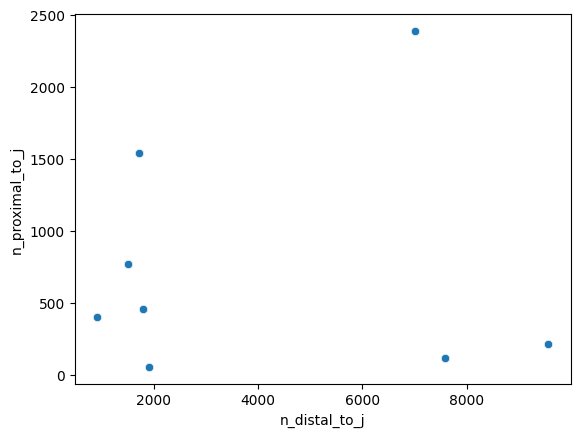

In [13]:
sns.scatterplot(data=mal_df, x='n_distal_to_j',y='n_proximal_to_j')

In [38]:
import pandas as pd
import os
parent_dir = '/work/magroup/skrieger/Syndri/data/xenium_noise_experiment/metrics_eval_layers_pooled_cosmx_X/'
metric_dirs = os.listdir(parent_dir)
tcell_files = sorted([os.path.join(parent_dir,x,'tcell_cosine_similarity_layers_pooled.csv') for x in metric_dirs if os.path.exists(os.path.join(parent_dir,x,'tcell_cosine_similarity_layers_pooled.csv'))])
tcell_df = pd.concat([pd.read_csv(f) for f in tcell_files]).reset_index(drop=True)
# tcell_df = pd.read_csv('/work/magroup/skrieger/Syndri/data/xenium_noise_experiment/metrics_eval_layers_pooled/B13_B13/tcell_cosine_similarity_layers_pooled.csv')
# sep_df = pd.read_csv('/work/magroup/skrieger/Syndri/data/xenium_noise_experiment/metrics_eval_layers_pooled/B10_B10/cell_type_separation_metrics_worstadj.csv')
# sep_df['tissue'].iloc[0]
# tcell_df['dropout']= tcell_df['tissue'].apply(lambda x: x.split('_')[-1])

# tcell_df['input_layer'].unique()

In [39]:
tcell_df['counts_layer'].unique()
# tcell_df[tcell_df['condition']=='uncorrected']['counts_layer'].unique()
# tcell_df['reference_cell_type'].unique()

array(['X', 'split_purified_counts_X'], dtype=object)

In [40]:
tcell_df

,tissue,source_file,condition,spatial_counts_layer,reference_counts_layer,reference_cell_type_key,cosine_similarity,n_spatial_cells,n_reference_cells,n_shared_genes,...,group_admix_prob_thresholds,group_probability_removal_scales,group_achieved_removed_fractions,input_layer,evaluation_method,probability_layer,counts_layer,sample_replicate,dropout_label,dropout_fraction
0,cosmx_nsclc_Lung12_adata_annotated_dropout_1pct,/work/magroup/skrieger/Syndri/data/xenium_nois...,uncorrected,X,X,cell_type,0.703088,2276.0,6316.0,957.0,...,NaN,NaN,NaN,X,baseline,NaN,X,Lung12,0pct,0.0
1,cosmx_nsclc_Lung12_adata_annotated_dropout_1pct,/work/magroup/skrieger/Syndri/data/xenium_nois...,uncorrected,X,X,cell_type,0.712462,1310.0,5401.0,957.0,...,NaN,NaN,NaN,X,baseline,NaN,X,Lung12,0pct,0.0
2,cosmx_nsclc_Lung12_adata_annotated_dropout_1pct,/work/magroup/skrieger/Syndri/data/xenium_nois...,uncorrected,X,X,cell_type,0.681377,18.0,1139.0,957.0,...,NaN,NaN,NaN,X,baseline,NaN,X,Lung12,0pct,0.0
3,cosmx_nsclc_Lung12_adata_annotated_dropout_1pct,/work/magroup/skrieger/Syndri/data/xenium_nois...,syndri_cleaned_removed_frac_0.01,_metrics_raw_cleaned_admixed_removed_frac_0_01,X,cell_type,0.703109,2276.0,6316.0,957.0,...,"{""B-cell"": null, ""DC"": null, ""NK"": null, ""T CD...","{""B-cell"": 0.0729467523648256, ""DC"": 0.0720482...","{""B-cell"": 0.01, ""DC"": 0.01, ""NK"": 0.01, ""T CD...",X,syndri,admix_probs_X,X,Lung12,0pct,0.0
4,cosmx_nsclc_Lung12_adata_annotated_dropout_1pct,/work/magroup/skrieger/Syndri/data/xenium_nois...,syndri_cleaned_removed_frac_0.01,_metrics_raw_cleaned_admixed_removed_frac_0_01,X,cell_type,0.712536,1310.0,5401.0,957.0,...,"{""B-cell"": null, ""DC"": null, ""NK"": null, ""T CD...","{""B-cell"": 0.0729467523648256, ""DC"": 0.0720482...","{""B-cell"": 0.01, ""DC"": 0.01, ""NK"": 0.01, ""T CD...",X,syndri,admix_probs_X,X,Lung12,0pct,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
197,cosmx_nsclc_Lung6_adata_annotated_dropout_1pct,/work/magroup/skrieger/Syndri/data/xenium_nois...,mlp_cleaned_removed_frac_0.2,_metrics_raw_cleaned_admixed_removed_frac_0_2,X,cell_type,0.757448,1118.0,6316.0,957.0,...,"{""B-cell"": null, ""DC"": null, ""NK"": null, ""T CD...","{""B-cell"": 1.4312622635364494, ""DC"": 1.0853124...","{""B-cell"": 0.2, ""DC"": 0.20000000000000004, ""NK...",X,mlp,mlp_admix_probs_X,X,Lung6,0pct,0.0
198,cosmx_nsclc_Lung6_adata_annotated_dropout_1pct,/work/magroup/skrieger/Syndri/data/xenium_nois...,mlp_cleaned_removed_frac_0.2,_metrics_raw_cleaned_admixed_removed_frac_0_2,X,cell_type,0.795756,319.0,1139.0,957.0,...,"{""B-cell"": null, ""DC"": null, ""NK"": null, ""T CD...","{""B-cell"": 1.4312622635364494, ""DC"": 1.0853124...","{""B-cell"": 0.2, ""DC"": 0.20000000000000004, ""NK...",X,mlp,mlp_admix_probs_X,X,Lung6,0pct,0.0
199,cosmx_nsclc_Lung6_adata_annotated_dropout_1pct,/work/magroup/skrieger/Syndri/data/xenium_nois...,split,_metrics_split_counts,X,cell_type,0.805470,1230.0,5401.0,957.0,...,NaN,NaN,NaN,X,split,NaN,split_purified_counts_X,Lung6,0pct,0.0
200,cosmx_nsclc_Lung6_adata_annotated_dropout_1pct,/work/magroup/skrieger/Syndri/data/xenium_nois...,split,_metrics_split_counts,X,cell_type,0.729299,1118.0,6316.0,957.0,...,NaN,NaN,NaN,X,split,NaN,split_purified_counts_X,Lung6,0pct,0.0


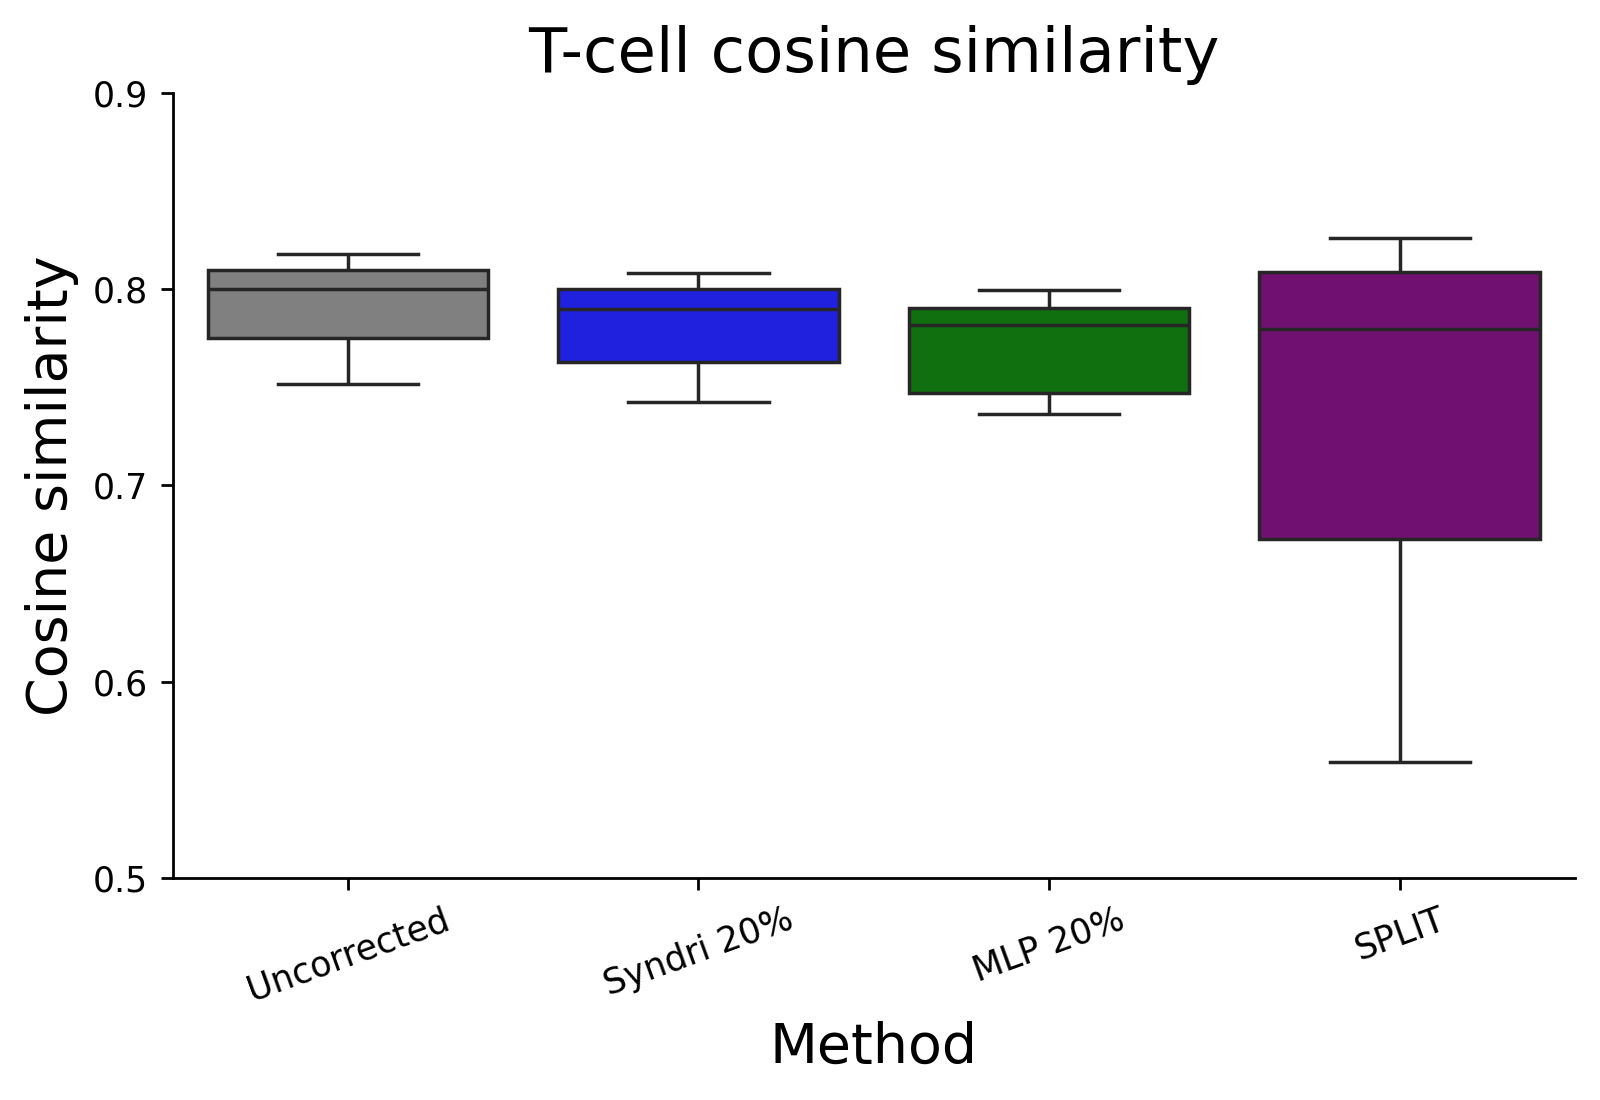

In [43]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

plot_df = tcell_df.copy()

conditions = [
    "uncorrected",
    "syndri_cleaned_removed_frac_0.2",
    "mlp_cleaned_removed_frac_0.2",
    "split",
]

condition_labels = {
    "uncorrected": "Uncorrected",
    "syndri_cleaned_removed_frac_0.2": "Syndri 20%",
    "mlp_cleaned_removed_frac_0.2": "MLP 20%",
    "split": "SPLIT",
}

colors = ["gray", "blue", "green", "purple"]

plot_df = plot_df.loc[
    plot_df["condition"].isin(conditions)
    & plot_df["dropout_fraction"].eq(0.00)
].copy()

plot_df["condition_label"] = plot_df["condition"].map(condition_labels)

# Enforce the intended plotting order
label_order = [condition_labels[c] for c in conditions]

plot_df["condition_label"] = pd.Categorical(
    plot_df["condition_label"],
    categories=label_order,
    ordered=True,
)

palette = dict(zip(label_order, colors))

fig, ax = plt.subplots(figsize=(6.5, 4.5), dpi=250)

# Distribution summary
sns.boxplot(
    data=plot_df,
    x="condition_label",
    y="cosine_similarity",
    order=label_order,
    hue="condition_label",
    palette=palette,
    legend=False,
    ax=ax,
    showfliers=False,
)

# Reproducible horizontal jitter
rng = np.random.default_rng(42)
jitter_width = 0.10

for x_position, condition_label in enumerate(label_order):
    group = plot_df.loc[
        plot_df["condition_label"].eq(condition_label)
    ].copy()

    jitter = rng.uniform(
        -jitter_width,
        jitter_width,
        size=len(group),
    )
    x_values = x_position + jitter

    # Individual observations
    # ax.scatter(
    #     x_values,
    #     group["cosine_similarity"],
    #     color="black",
    #     alpha=0.55,
    #     s=14,
    #     zorder=3,
    # )

    # Replicate annotations
    # for x, (_, row) in zip(x_values, group.iterrows()):
    #     ax.annotate(
    #         str(row["sample_replicate"]),
    #         xy=(x, row["cosine_similarity"]),
    #         xytext=(3, 2),
    #         textcoords="offset points",
    #         fontsize=6,
    #         alpha=0.8,
    #         ha="left",
    #         va="bottom",
    #         zorder=4,
    #     )

ax.set_xlabel("Method", fontsize=16)
ax.set_ylabel("Cosine similarity", fontsize=16)
ax.set_yticks(np.arange(0.5, 0.91, 0.1))
ax.set_title("T-cell cosine similarity", fontsize=18)

ax.tick_params(axis="x", labelrotation=20)
sns.despine(ax=ax)

fig.tight_layout()
plt.show()